# TP1 — Machine Learning 2
## Prédiction de la direction du marché : modélisation, limites et comparaison de modèles

**Problématique :** peut-on prédire si le marché va monter ou descendre demain à partir d'informations passées ?


---
# PARTIE 0 — Introduction financière

 **Concept**

- **Prix de clôture** $P_t$ : valeur de l'actif à la fin de la journée $t$.
- **Rendement** : $r_t = \dfrac{P_t - P_{t-1}}{P_{t-1}}$. Exemple : le prix passe de 100 à 102 → $r_t = 2\,\%$. On travaille avec les rendements plutôt qu'avec les prix car ils sont comparables d'une période à l'autre.
- **Volatilité** : écart-type des rendements → mesure l'incertitude, « à quel point ça bouge ».
- **Volume** : quantité échangée → mesure l'activité du marché.

Le problème ML est une **classification binaire** : $Y_t = 1$ si le marché monte en $t+1$, $0$ sinon.

 **Réponses**

**1. Pourquoi ce problème est-il difficile ?**
- **Signal très faible, bruit très fort** : les rendements journaliers ressemblent presque à du bruit aléatoire ; la part prévisible est minime.
- **Efficience des marchés** : toute information publique (dont les prix passés) est très vite intégrée dans le prix. Si un motif simple permettait de gagner, les traders l'exploiteraient et il disparaîtrait.
- **Non-stationnarité** : les lois statistiques changent dans le temps (crises, Covid 2020, hausse des taux 2022). Ce qui marchait en 2016 ne marche pas forcément en 2022.
- **Information manquante** : les prix dépendent d'événements extérieurs (annonces, géopolitique) absents de nos variables.
- **Classes presque équilibrées** : environ 53-55 % de jours haussiers, donc on part d'une base proche du hasard.

**2. Pourquoi ne peut-on pas prédire parfaitement ?**
Parce que le futur dépend d'informations **qui n'existent pas encore** au temps $t$ (nouvelles imprévisibles). Une part du mouvement est intrinsèquement aléatoire : même le meilleur modèle possible a une **erreur irréductible** (erreur de Bayes) élevée. De plus, si une prédiction parfaite existait, son exploitation changerait elle-même les prix.

---
# PARTIE 1 — Construction du dataset

## 1.1 Chargement

 Le ticker **SPY** est un fonds indiciel qui réplique le S&P 500 (les 500 plus grosses entreprises américaines). On récupère 8 ans de données journalières (2015-2022) avec `yfinance`.

 **Piège des versions récentes de yfinance** : `yf.download` renvoie des colonnes à deux niveaux (`('Close', 'SPY')`). La ligne `droplevel` ci-dessous remet des colonnes simples, sinon `data['Close']` renvoie un tableau au lieu d'une série.

In [8]:
%pip install yfinance pandas numpy matplotlib seaborn scikit-learn tensorflow
import yfinance as yf
import pandas as pd
import numpy as np

data = yf.download("SPY", start="2015-01-01", end="2023-01-01")

# Versions récentes de yfinance : colonnes MultiIndex ('Close', 'SPY') -> on aplatit
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.droplevel(1)

data = data[['Close', 'Volume']]
data.dropna(inplace=True)
data.head()

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
[*********************100%***********************]  1 of 1 completed


Price,Close,Volume
Date,,
2015-01-02,169.267532,121465900
2015-01-05,166.210587,169632600
2015-01-06,164.645081,209151400
2015-01-07,166.696762,125346700
2015-01-08,169.654800,147217800


## 1.2 Fonction de features

 **Concept**
- `.pct_change()` calcule $\frac{x_t - x_{t-1}}{x_{t-1}}$ (variation relative).
- `.rolling(window=5)` calcule une statistique sur une **fenêtre glissante** des 5 derniers jours (aujourd'hui inclus).
- `.shift(5)` décale la série de 5 lignes vers le bas : à la ligne $t$, on lit la valeur de $t-5$ → **accès au passé**.

Les deux `TODO` :
- **momentum** $= P_t - P_{t-5}$ : de combien le prix a bougé en 5 jours (tendance récente).
- **volume_change** $= \frac{V_t - V_{t-1}}{V_{t-1}}$ : variation relative du volume.

In [2]:
def build_features(df):
    df = df.copy()

    # Rendement
    df['return'] = df['Close'].pct_change()

    # Volatilité : écart-type sur 5 jours
    df['volatility'] = df['return'].rolling(window=5).std()

    # Moyenne mobile
    df['ma'] = df['Close'].rolling(window=5).mean()

    # TODO : momentum = différence entre prix actuel et prix il y a 5 jours
    df['momentum'] = df['Close'] - df['Close'].shift(5)

    # TODO : variation du volume = taux de variation du volume
    df['volume_change'] = df['Volume'].pct_change()

    return df

## 1.3 Fonction target

 **Concept** : on veut $Y_t = 1$ si le rendement de **demain** $r_{t+1} > 0$.
`.shift(-1)` décale la série vers le **haut** : à la ligne $t$, on lit la valeur de $t+1$.

 **Subtilité** : la dernière ligne n'a pas de « demain », donc $r_{t+1}$ vaut `NaN`. Or `NaN > 0` vaut `False`, ce qui donnerait une target à 0 au lieu d'une valeur manquante. On garde donc explicitement `NaN` pour que le `dropna()` supprime cette ligne.

In [6]:
def build_target(df):
    df = df.copy()

    # TODO : target = 1 si rendement futur > 0
    future_return = df['Close'].pct_change().shift(-1)   # r_{t+1} placé sur la ligne t
    df['target'] = np.where(future_return.isna(), np.nan, (future_return > 0).astype(int))

    return df

## 1.4 Pipeline complet

 **Point clé** : les features ne doivent utiliser **que le passé** ; seule la target regarde le futur (c'est ce qu'on cherche à prédire).

In [9]:
df = build_features(data)
df = build_target(df)
df = df.dropna()
df['target'] = df['target'].astype(int)

print(df.shape)
print(df['target'].value_counts(normalize=True))   # proportion de jours haussiers
df.head()

(2008, 8)
target
1    0.539343
0    0.460657
Name: proportion, dtype: float64


Price,Close,Volume,return,volatility,ma,momentum,volume_change,target
Date,,,,,,,,
2015-01-09,168.295273,158567300,-0.008013,0.015360,167.100500,-0.972260,0.077093,0
2015-01-12,166.976883,144396100,-0.007834,0.013034,167.253760,0.766296,-0.089370,0
2015-01-13,166.507233,214553300,-0.002813,0.012010,167.626190,1.862152,0.485866,0
2015-01-14,165.501953,192991100,-0.006037,0.010899,167.387228,-1.194809,-0.100498,0
2015-01-15,163.985855,176613900,-0.009161,0.002479,166.253439,-5.668945,-0.084860,1


 **Réponses**

**1. Pourquoi utilise-t-on `.shift(-1)` ?**
Pour aligner sur la même ligne les informations du jour $t$ (les features) et ce qui se passe au jour $t+1$ (la target). Le modèle apprend ainsi « avec ce que je sais aujourd'hui, est-ce que demain sera haussier ? ».

**2. Que se passe-t-il si on ne le fait pas ?**
La target devient « le rendement d'aujourd'hui est-il positif ? ». Or la feature `return` **est** ce rendement : le modèle a la réponse dans ses entrées. On obtient une accuracy proche de 100 %, mais on ne prédit rien : on décrit le présent.

**3. Quel type d'erreur cela introduit ?**
Une **fuite d'information (data leakage)**, plus précisément un biais d'anticipation (*look-ahead bias*) : l'erreur est de conception, pas de modèle. Les performances mesurées sont **artificiellement optimistes** et s'effondrent en conditions réelles.

**4. En quoi utiliser des informations futures dans les features conduit-il à une fuite ?**
En production, au moment de prédire, ces informations futures **n'existent pas encore**. Pendant l'entraînement, le modèle apprend à s'appuyer sur elles ; une fois déployé, il ne les a plus et ses prédictions deviennent mauvaises. Exemples de fuite accidentelle : une moyenne mobile centrée (`rolling(..., center=True)`), une normalisation calculée sur tout le dataset (dont le test), ou un mélange aléatoire des données avant le split.

---
# PARTIE 2 — Analyse des données

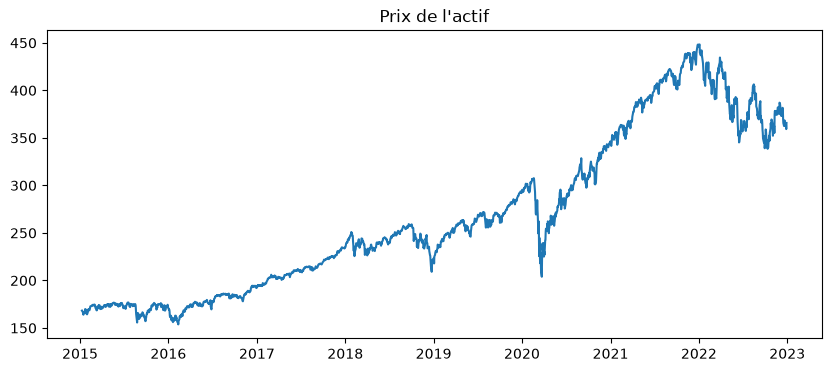

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 2.1 Visualisation
plt.figure(figsize=(10, 4))
plt.plot(df['Close'])
plt.title("Prix de l'actif")
plt.show()

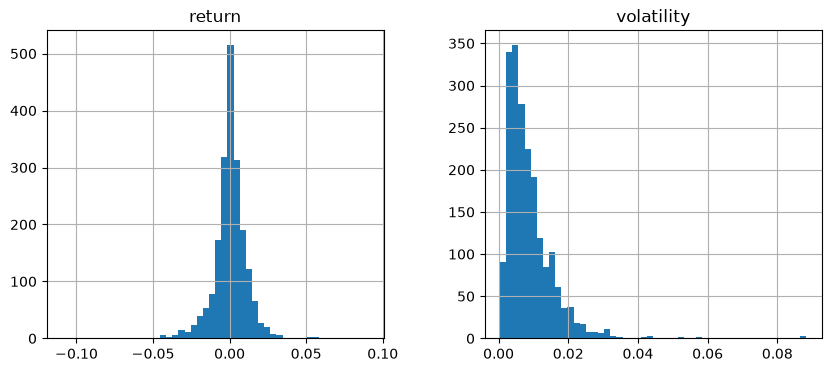

In [8]:
# 2.2 Distribution
df[['return', 'volatility']].hist(bins=50, figsize=(10, 4))
plt.show()

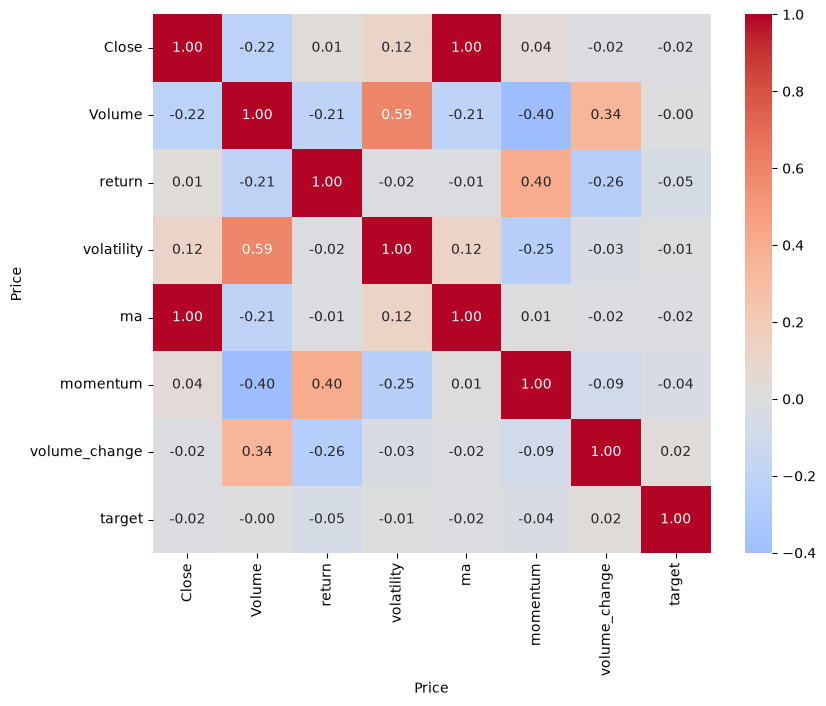

Price
return          -0.052336
momentum        -0.036813
Close           -0.020003
ma              -0.018525
volatility      -0.010899
Volume          -0.001409
volume_change    0.024113
Name: target, dtype: float64

In [9]:
# 2.3 Corrélations
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

# Zoom sur la corrélation de chaque variable avec la target
df.corr()['target'].drop('target').sort_values()

 **Lecture des graphiques**
- **Prix** : tendance haussière de long terme avec des chocs (Covid mars 2020, baisse 2022). La moyenne et la variance changent dans le temps → série **non stationnaire**.
- **Rendements** : distribution centrée sur 0, en cloche, mais avec des **queues épaisses** (des jours extrêmes plus fréquents que dans une loi normale).
- **Volatilité** : asymétrique, toujours positive, avec des pics lors des crises.

 **Réponses**

**1. Les variables sont-elles fortement corrélées à la target ?**
Non. Les corrélations avec `target` sont toutes très proches de 0 (de l'ordre de ±0,05). En revanche, certaines features sont très corrélées **entre elles** : `Close` et `ma` (≈ 1, car la moyenne mobile suit le prix), `return` et `momentum`. C'est de la **redondance** (multicolinéarité).

**2. Peut-on s'attendre à une forte performance ?**
Non. On peut s'attendre à une accuracy proche de la proportion de jours haussiers (≈ 53-55 %), soit à peine mieux que le hasard.

**3. Pourquoi ?**
Une corrélation quasi nulle signifie qu'il n'y a pas de lien **linéaire** exploitable entre les features et la target. Il peut exister des liens non linéaires (c'est ce que testeront le Random Forest et le réseau de neurones), mais ils sont faibles et instables à cause de l'efficience des marchés et de la non-stationnarité.

**Remarque sur la stationnarité** : `Close` et `ma` sont des niveaux de prix (≈ 200 $ en 2016, ≈ 450 $ en 2021). Le modèle apprend sur des valeurs qu'il ne reverra jamais dans le test : la période de test (2021-2022) a des prix hors de la plage d'entraînement. Les rendements, eux, gardent la même échelle dans le temps, d'où leur intérêt.

---
# PARTIE 3 — Pipeline ML

 **Concept** : avec des séries temporelles, on **coupe dans le temps** : les 80 % les plus anciens pour l'entraînement, les 20 % les plus récents pour le test. C'est la seule façon de simuler la réalité : entraîner sur le passé, prédire le futur.

In [10]:
# 3.1 Sélection des variables
features = ['return', 'volatility', 'ma', 'momentum', 'volume_change']
X = df[features]
y = df['target']

# 3.2 Split temporel
def temporal_split(X, y, ratio=0.8):
    n = len(X)
    split = int(n * ratio)
    X_train = X.iloc[:split]
    X_test = X.iloc[split:]
    y_train = y.iloc[:split]
    y_test = y.iloc[split:]
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = temporal_split(X, y)
print("Train :", X_train.index.min().date(), "->", X_train.index.max().date(), len(X_train))
print("Test  :", X_test.index.min().date(), "->", X_test.index.max().date(), len(X_test))

Train : 2015-01-09 -> 2021-05-26 1606
Test  : 2021-05-27 -> 2022-12-29 402


 **Pourquoi ne pas mélanger les données ?**
1. **Fuite temporelle** : avec `shuffle`, le train contiendrait des jours de 2022 et le test des jours de 2016. Le modèle apprendrait sur le futur pour prédire le passé, ce qui est impossible en réalité.
2. **Dépendance entre jours voisins** : les features utilisent des fenêtres de 5 jours, donc deux jours consécutifs partagent presque les mêmes informations. Si l'un est dans le train et l'autre dans le test, le modèle « reconnaît » le test : score gonflé.
3. **Non-stationnarité** : le vrai défi est de généraliser à une **nouvelle période**. Le mélange masque ce problème et donne une estimation trop optimiste.

---
# PARTIE 4 — Modèle linéaire : régression logistique

 **Concept**
La régression logistique calcule un score linéaire puis le transforme en probabilité avec la sigmoïde :
$$P(Y=1 \mid x) = \sigma(w^\top x + b) = \frac{1}{1 + e^{-(w_1 x_1 + \dots + w_5 x_5 + b)}}$$
On prédit 1 si cette probabilité dépasse 0,5, c'est-à-dire si $w^\top x + b > 0$. La **frontière de décision** est donc un hyperplan (une « droite » en dimension 5).

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)
print("Accuracy LR :", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr, zero_division=0))
print("Matrice de confusion :\n", confusion_matrix(y_test, y_pred_lr))

# Référence naïve : toujours prédire la classe majoritaire du train
baseline = (y_test == y_train.mode()[0]).mean()
print("Baseline (classe majoritaire) :", round(baseline, 3))

Accuracy LR : 0.4975124378109453
              precision    recall  f1-score   support

           0       1.00      0.01      0.02       204
           1       0.49      1.00      0.66       198

    accuracy                           0.50       402
   macro avg       0.75      0.50      0.34       402
weighted avg       0.75      0.50      0.34       402

Matrice de confusion :
 [[  2 202]
 [  0 198]]
Baseline (classe majoritaire) : 0.493


 **L'accuracy suffit-elle à juger un modèle de classification ?**
Non. Si 54 % des jours sont haussiers, un modèle qui prédit **toujours 1** obtient 54 % d'accuracy sans rien avoir appris. Il faut regarder :
- la **matrice de confusion** : le modèle prédit-il les deux classes, ou une seule ?
- la **précision** (quand je prédis « hausse », ai-je raison ?) et le **rappel** (parmi les vraies hausses, combien j'en détecte ?) **par classe**, et le **F1-score** ;
- la comparaison à une **baseline** (classe majoritaire) ;
- en finance, la métrique qui compte vraiment est souvent le **gain** d'une stratégie : se tromper un jour de −5 % coûte bien plus que se tromper un jour de +0,1 %.

C'est typiquement ce qui arrive ici : regarde dans le `classification_report` si le rappel de la classe 0 est proche de 0 ; si oui, le modèle prédit presque toujours « hausse ».

In [12]:
# 4.3 Analyse des coefficients
pd.Series(model_lr.coef_[0], index=features)

return          -0.429956
volatility      -0.012185
ma               0.001191
momentum        -0.014160
volume_change    0.180408
dtype: float64

 Les features ne sont pas à la même échelle (`ma` ≈ 300, `return` ≈ 0,001) : la taille brute d'un coefficient ne mesure donc pas l'importance de la variable. Pour comparer, il faudrait standardiser les features (voir partie 11).

 **Réponses**

**1. Quelle est la forme mathématique du modèle ?**
$P(Y=1\mid x) = \sigma(w^\top x + b)$ avec $\sigma(z) = \frac{1}{1+e^{-z}}$. C'est un modèle **linéaire dans le log-odds** : $\log\frac{P}{1-P} = w^\top x + b$. Chaque coefficient $w_j$ indique de combien le log-odds augmente quand $x_j$ augmente d'une unité, les autres étant fixes. La frontière de décision est un hyperplan.

**2. Peut-il capturer des interactions ?**
Non, pas tout seul. Chaque variable agit de façon **additive et indépendante** : l'effet du rendement est le même que la volatilité soit forte ou faible. Pour capturer une interaction (par exemple « un fort rendement n'a pas le même sens en période calme qu'en période agitée »), il faut **créer à la main** la variable $x_1 \times x_2$ (partie 5).

**3. Pourquoi peut-il échouer ?**
- Les relations éventuelles entre features et target sont **non linéaires** (effets de seuil, régimes de marché) : un hyperplan ne peut pas les représenter → **biais élevé (sous-apprentissage)**.
- Features non standardisées et redondantes (`ma` ≈ `Close`) → coefficients instables et difficiles à interpréter.
- Le signal est presque inexistant : le modèle tend vers la solution « toujours prédire la classe majoritaire ».

---
# PARTIE 5 — Feature engineering

 **Concept** : un modèle linéaire sur $x$ ne voit que des droites. Mais si on lui donne des **transformations** de $x$ (produits, carrés…), il devient linéaire en ces nouvelles variables tout en étant **non linéaire en $x$**. On note $\varphi(x)$ cette transformation : le modèle devient $\sigma(w^\top \varphi(x) + b)$.

Interactions choisies (avec leur intuition financière) :
- `return_vol` = rendement × volatilité : un même rendement n'a pas le même sens en période calme ou agitée.
- `mom_vol` = momentum × volatilité : une tendance est-elle fiable quand le marché est nerveux ?
- `return_volchg` = rendement × variation de volume : un mouvement de prix accompagné de beaucoup de volume est souvent jugé plus « significatif ».
- `return_sq` = rendement² : l'amplitude du mouvement sans son signe (un grand mouvement dans un sens ou l'autre).

In [13]:
def add_interactions(X):
    X_new = X.copy()
    # TODO : créer au moins 3 interactions entre variables
    X_new['return_vol'] = X['return'] * X['volatility']
    X_new['mom_vol'] = X['momentum'] * X['volatility']
    X_new['return_volchg'] = X['return'] * X['volume_change']
    X_new['return_sq'] = X['return'] ** 2
    return X_new

X_inter = add_interactions(X)
X_train_i, X_test_i, y_train_i, y_test_i = temporal_split(X_inter, y)

# 5.2 Ré-entraînement et comparaison
model_lr_inter = LogisticRegression(max_iter=1000)
model_lr_inter.fit(X_train_i, y_train_i)
y_pred_lr_inter = model_lr_inter.predict(X_test_i)

print("LR simple   :", round(accuracy_score(y_test, y_pred_lr), 4))
print("LR enrichie :", round(accuracy_score(y_test_i, y_pred_lr_inter), 4))
print(classification_report(y_test_i, y_pred_lr_inter, zero_division=0))

LR simple   : 0.4975
LR enrichie : 0.5
              precision    recall  f1-score   support

           0       0.80      0.02      0.04       204
           1       0.50      0.99      0.66       198

    accuracy                           0.50       402
   macro avg       0.65      0.51      0.35       402
weighted avg       0.65      0.50      0.35       402



 **Réponses**

**1. Pourquoi ces variables (peuvent) améliorer le modèle ?**
Elles permettent au modèle linéaire de représenter des effets **conditionnels** qu'il ne pouvait pas voir : l'effet du rendement peut maintenant dépendre de la volatilité ou du volume. La frontière de décision, toujours un hyperplan dans l'espace enrichi, devient **courbe** dans l'espace d'origine. On réduit le **biais** du modèle.

*Nuance honnête :* sur ce problème, le gain est en général faible, voire nul : on ne crée pas de signal là où il n'y en a presque pas, et ajouter des variables augmente aussi un peu la variance (risque de surapprentissage). Compare tes deux accuracies et conclus en fonction : une amélioration de moins d'un point n'est pas significative sur ~400 jours de test.

**2. Quel lien avec $\varphi(x)$ ?**
`add_interactions` **est** une fonction $\varphi$ : elle envoie $x \in \mathbb{R}^5$ vers $\varphi(x) \in \mathbb{R}^9$. Le modèle reste linéaire **en $\varphi(x)$** mais devient non linéaire **en $x$**. C'est exactement l'idée des noyaux (SVM) et des réseaux de neurones, avec une différence clé :
- ici, $\varphi$ est **choisie à la main** (feature engineering, il faut connaître le métier) ;
- un réseau de neurones **apprend** $\varphi$ automatiquement dans ses couches cachées ;
- un noyau (kernel trick) utilise un $\varphi$ implicite, parfois de dimension infinie.

---
# PARTIE 6 — Random Forest

 **Concept**
- Un **arbre de décision** découpe l'espace par des questions successives du type « volatilité > 0,012 ? ». Il produit des régions rectangulaires → non linéaire par construction, et capture naturellement des interactions (une question sur la volatilité, puis sur le rendement dans cette branche).
- Seul, un arbre profond surapprend (variance élevée).
- Un **Random Forest** entraîne beaucoup d'arbres (ici 300), chacun sur un **échantillon bootstrap** des données et en tirant au hasard un sous-ensemble de variables à chaque découpage, puis fait **voter** les arbres. Le vote moyenne les erreurs → variance réduite.
- `max_depth=5` limite la profondeur de chaque arbre → limite la complexité.

In [14]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, max_depth=5, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Accuracy RF :", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, zero_division=0))

# Importance des variables (bonus)
pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)

Accuracy RF : 0.5074626865671642
              precision    recall  f1-score   support

           0       0.52      0.32      0.40       204
           1       0.50      0.70      0.58       198

    accuracy                           0.51       402
   macro avg       0.51      0.51      0.49       402
weighted avg       0.51      0.51      0.49       402



return           0.244985
ma               0.206206
momentum         0.202619
volume_change    0.180793
volatility       0.165398
dtype: float64

 **Réponses**

**1. Pourquoi RF capture-t-il des non-linéarités ?**
Chaque arbre découpe l'espace en régions par des **seuils** successifs : la prédiction est une fonction **constante par morceaux**, pas une droite. En enchaînant des découpages sur différentes variables, un arbre modélise automatiquement des **interactions** (« si volatilité forte ET rendement négatif, alors… ») sans qu'on ait à créer les produits à la main. La moyenne de centaines d'arbres donne une frontière de décision complexe et non linéaire.

**2. Est-il plus robuste ?**
Oui, sur plusieurs points :
- **Moins de variance** qu'un arbre seul grâce au bagging et au vote (les erreurs des arbres se compensent).
- **Insensible à l'échelle** des variables (seuls les seuils comptent) → pas besoin de standardiser, contrairement à LR et NN.
- Assez **robuste aux valeurs extrêmes** et aux variables inutiles.

Mais il a ses limites : il ne sait **pas extrapoler**. Avec `ma` et `Close` dans les features, la période de test a des prix supérieurs à tout ce qui a été vu à l'entraînement : l'arbre range tous ces jours dans la même feuille « prix élevé ». Et la robustesse ne crée pas de signal : sur ce problème, l'accuracy reste proche de la baseline.

---
# PARTIE 7 — Réseau de neurones

 **Concept**
Architecture : 5 entrées → 64 neurones (ReLU) → 32 neurones (ReLU) → 1 neurone (sigmoïde).
- Chaque couche calcule $h = \text{ReLU}(Wx + b)$ : une transformation linéaire suivie d'une non-linéarité. Les couches cachées **apprennent $\varphi(x)$** ; la dernière couche est… une régression logistique sur $\varphi(x)$.
- Nombre de paramètres : $5\times64+64 + 64\times32+32 + 32+1 = 2\,497$ pour ~1 600 jours d'entraînement : c'est beaucoup → risque de surapprentissage.
- **Perte** : *binary cross-entropy* ; **optimiseur** : Adam ; **epoch** = un passage complet sur les données d'entraînement.

 Comme le TP le signale, utiliser `X_test` comme `validation_data` est une facilité pédagogique : en pratique on réserve un jeu de validation séparé (fait proprement en partie 11 bonus).

In [15]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

tf.random.set_seed(42)

def build_model(input_dim, hidden1=64, hidden2=32):
    model = Sequential([
        Input(shape=(input_dim,)),          # équivalent moderne de input_shape=(input_dim,)
        Dense(hidden1, activation='relu'),
        Dense(hidden2, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model

model_nn = build_model(X_train.shape[1])
history = model_nn.fit(
    X_train, y_train,
    epochs=50,
    validation_data=(X_test, y_test),
    verbose=0
)
y_pred_nn = (model_nn.predict(X_test, verbose=0).ravel() > 0.5).astype(int)
print("Accuracy NN :", accuracy_score(y_test, y_pred_nn))
print("Répartition des prédictions :", np.bincount(y_pred_nn, minlength=2))

Accuracy NN : 0.4975124378109453
Répartition des prédictions : [  2 400]


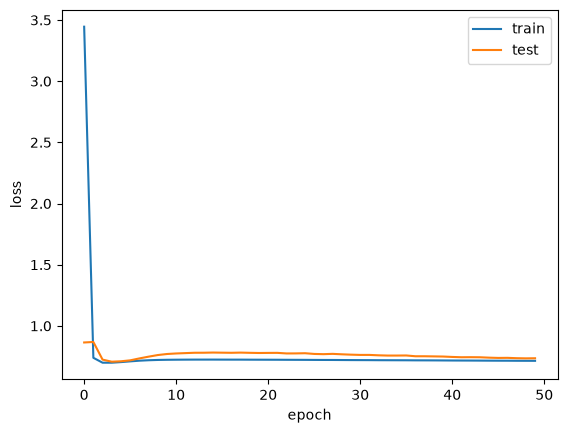

In [16]:
# 7.3 Visualisation
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.xlabel("epoch"); plt.ylabel("loss")
plt.legend()
plt.show()

 **Comment lire la courbe**
- Les deux courbes descendent ensemble → le modèle apprend quelque chose de généralisable.
- La courbe *train* descend mais la courbe *test* stagne ou **remonte** → **surapprentissage** : le modèle mémorise le bruit du train.
- Courbes en dents de scie / très irrégulières → instabilité, souvent due aux features **non standardisées** (`ma` ≈ 300 à côté de `return` ≈ 0,001 : les gradients sont dominés par `ma`).

 **Réponses** (à confirmer avec ta courbe)

**1. Y a-t-il un problème de surapprentissage ?**
Typiquement oui : la loss d'entraînement continue de baisser tandis que la loss de test stagne autour de 0,69 (= $\ln 2$, la perte d'un modèle qui répond 50/50) ou remonte. Autre signe possible : le réseau prédit presque toujours la même classe (regarde la répartition des prédictions ci-dessus), ce qui montre qu'il n'a pas trouvé de vrai signal.

**2. Pourquoi ?**
- Beaucoup de paramètres (~2 500) pour peu de données (~1 600 exemples) et un signal quasi nul : le réseau a assez de capacité pour **mémoriser le bruit** au lieu de la structure.
- 50 epochs sans *early stopping* ni régularisation (dropout, L2).
- Données non stationnaires : ce qui est appris sur 2015-2021 ne vaut pas pour 2021-2022.

**3. Lien biais/variance ?**
L'erreur de généralisation se décompose en **biais² + variance + bruit irréductible**.
- Modèle simple (LR) : **biais fort** (ne peut pas représenter de relations complexes), **variance faible** (stable d'un échantillon à l'autre).
- Modèle complexe (NN) : **biais faible**, **variance forte** (très sensible aux données d'entraînement exactes).
Le NN se situe du côté « variance » : il colle trop au train. Ici, le terme **bruit irréductible** est énorme : aucun modèle ne peut descendre en dessous, et augmenter la complexité fait surtout monter la variance.

---
# PARTIE 8 — Expérience avancée : très peu de données

 On réentraîne les trois modèles sur seulement **100 jours**, et on répète l'expérience sur plusieurs initialisations / tirages pour mesurer la **stabilité** (l'écart-type des résultats). C'est une mesure directe de la **variance** du modèle.

In [17]:
X_small = X_train[:100]
y_small = y_train[:100]

res_small = {'LR': [], 'RF': [], 'NN': []}
for seed in range(5):
    lr_s = LogisticRegression(max_iter=1000).fit(X_small, y_small)
    res_small['LR'].append(accuracy_score(y_test, lr_s.predict(X_test)))

    rf_s = RandomForestClassifier(n_estimators=300, max_depth=5, random_state=seed).fit(X_small, y_small)
    res_small['RF'].append(accuracy_score(y_test, rf_s.predict(X_test)))

    tf.random.set_seed(seed)
    nn_s = build_model(X_small.shape[1])
    nn_s.fit(X_small, y_small, epochs=50, verbose=0)
    res_small['NN'].append(accuracy_score(y_test, (nn_s.predict(X_test, verbose=0).ravel() > 0.5).astype(int)))

pd.DataFrame({m: {'moyenne': np.mean(v), 'écart-type': np.std(v), 'min': np.min(v), 'max': np.max(v)}
              for m, v in res_small.items()}).T.round(4)

,moyenne,écart-type,min,max
LR,0.5075,0.0000,0.5075,0.5075
RF,0.5124,0.0117,0.4950,0.5249
NN,0.4881,0.0037,0.4826,0.4925


 **Réponses**

**1. Quel modèle est le plus stable ?**
En général la **régression logistique** : elle est déterministe (écart-type nul sur les répétitions) et son accuracy change peu entre 100 exemples et le train complet. Le **NN** est le moins stable : ses résultats varient selon l'initialisation des poids, et il peut basculer entre « toujours 1 » et « toujours 0 ». Le RF est intermédiaire.

**2. Pourquoi ?**
- LR : 6 paramètres seulement, et un problème d'optimisation **convexe** → une solution unique, peu sensible aux données.
- RF : beaucoup plus de liberté, mais le vote de 300 arbres amortit la variance.
- NN : ~2 500 paramètres pour 100 exemples (25 paramètres par exemple !), optimisation **non convexe** dépendant de l'initialisation → il mémorise les 100 points et ses prédictions dépendent fortement du hasard.

**3. Quel lien avec la variance ?**
La variance d'un modèle mesure **à quel point il change quand on change les données d'entraînement**. Moins il y a de données, plus la variance pèse dans l'erreur. Les modèles complexes (grande capacité) ont la plus grande variance, donc ce sont eux qui souffrent le plus quand les données sont rares. D'où la règle : **peu de données → modèle simple**.

---
# PARTIE 9 — Comparaison finale

In [18]:
print("LR:", accuracy_score(y_test, y_pred_lr))
print("RF:", accuracy_score(y_test, y_pred_rf))
print("NN:", accuracy_score(y_test, y_pred_nn))
print("Baseline (classe majoritaire):", round(baseline, 4))

LR: 0.4975124378109453
RF: 0.5074626865671642
NN: 0.4975124378109453
Baseline (classe majoritaire): 0.4925


 **Analyse critique** (à adapter avec tes chiffres)

**1. Quel modèle est le meilleur ?**
Les trois modèles ont en général des accuracies très proches, autour de 50-55 %, **toutes proches de la baseline**. Des écarts de 1-2 points sur ~400 jours de test ne sont **pas statistiquement significatifs** (l'intervalle de confiance d'une accuracy sur 400 exemples est d'environ ±5 points). Conclusion honnête : **aucun modèle ne bat clairement la baseline** ; s'il faut en choisir un, on prend le plus simple parmi ceux qui ont le même score (souvent LR ou RF).

**2. Pourquoi ce n'est pas forcément le NN ?**
- Le NN est le plus **flexible**, mais la flexibilité n'aide que s'il y a une structure complexe à apprendre. Ici, il y a surtout du bruit : le NN apprend ce bruit (surapprentissage).
- Peu de données (~1 600 jours) pour beaucoup de paramètres.
- Pas de standardisation ni de régularisation dans le code du TP, alors que le NN y est très sensible.
- Les NN brillent sur des données massives et structurées (images, texte), pas sur 5 variables tabulaires bruitées.

**3. Quel compromis biais/variance observez-vous ?**
- **LR** : biais élevé, variance faible → stable mais trop simple.
- **RF (profondeur 5)** : compromis intermédiaire, la limite de profondeur et le vote contrôlent la variance.
- **NN** : biais faible, variance élevée → instable, sensible aux données et à l'initialisation.
Comme le bruit irréductible domine, réduire le biais n'apporte presque rien, alors qu'augmenter la variance coûte : **le compromis optimal est du côté des modèles simples / régularisés**.

---
# PARTIE 10 — Première synthèse

**Pourquoi le problème est difficile**
Les rendements journaliers sont dominés par le bruit : le marché intègre très vite l'information passée (efficience), les régimes changent dans le temps (non-stationnarité) et une grande partie des mouvements dépend d'événements futurs imprévisibles. Les corrélations features/target sont quasi nulles et l'erreur irréductible est très élevée.

**Pourquoi le modèle linéaire est limité**
La régression logistique ne trace qu'un hyperplan et traite chaque variable de façon additive : elle ne capture ni effets de seuil ni interactions. Sa force, la stabilité, en fait toutefois une bonne référence.

**Rôle du feature engineering**
Construire $\varphi(x)$ (interactions, carrés, indicateurs financiers) permet à un modèle simple d'exprimer des relations non linéaires tout en restant interprétable. C'est souvent le levier le plus efficace… à condition que les features apportent un vrai signal et n'utilisent que le passé (pas de fuite).

**Intérêt des NN**
Ils apprennent automatiquement $\varphi(x)$ et peuvent approcher des fonctions très complexes (approximateurs universels). Ils sont puissants avec beaucoup de données structurées, mais exigent standardisation, régularisation et validation rigoureuse.

**Dangers du surapprentissage**
Un modèle trop complexe mémorise le bruit du train : très bon score en entraînement, mauvais en production. En finance c'est particulièrement dangereux, car un backtest surappris donne l'illusion d'une stratégie rentable qui perd de l'argent en réel. S'y ajoutent le risque de fuite temporelle et le sur-réglage des hyperparamètres sur le jeu de test.

**Choix en production**
Privilégier le modèle **le plus simple** qui atteint la performance, stable dans le temps, interprétable et peu coûteux à réentraîner (souvent LR régularisée ou RF peu profond). Le valider avec un **split temporel glissant (walk-forward)**, un jeu de validation distinct, le comparer à une baseline et à une métrique métier (rendement d'une stratégie, avec frais de transaction), et surveiller sa dérive pour le réentraîner régulièrement.

---
# PARTIE 11 — Recherche du meilleur modèle

## 11.1 Régression logistique

 `C` est l'**inverse de la force de régularisation** (L2 par défaut). La régression logistique minimise :
$$\text{perte} = \underbrace{\frac{1}{2}\|w\|^2}_{\text{pénalité}} + C \sum_i \text{log-loss}_i$$
- **Petit `C`** → forte régularisation → coefficients poussés vers 0 → modèle plus simple (biais ↑, variance ↓).
- **Grand `C`** → faible régularisation → le modèle colle davantage aux données (biais ↓, variance ↑).

In [19]:
results_lr = []
for C in [0.01, 0.1, 1, 10]:
    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    results_lr.append((C, acc))

results_lr

[(0.01, 0.4925373134328358),
 (0.1, 0.4925373134328358),
 (1, 0.4975124378109453),
 (10, 0.49502487562189057)]

 **Réponses**

**1. Que contrôle le paramètre C ?**
L'inverse de l'intensité de la régularisation L2, c'est-à-dire la pénalité sur la taille des coefficients. Petit C = forte pénalité, grand C = faible pénalité.

**2. Pourquoi changer C modifie-t-il la généralisation ?**
Parce que C règle directement le **compromis biais/variance**. Une forte régularisation empêche le modèle de donner trop d'importance à une variable sur la base de quelques exemples (moins de surapprentissage) ; une régularisation trop forte écrase tous les coefficients et le modèle n'apprend plus rien (sous-apprentissage).

**3. Quelle valeur semble la meilleure ?**
À lire dans tes résultats. Sur des features non standardisées, il est fréquent que **toutes les valeurs de C donnent la même accuracy** : la régularisation agit surtout sur les variables à petite échelle, et le modèle finit par prédire la classe majoritaire. En cas d'égalité, on choisit le **plus petit C** (modèle le plus régularisé, donc le plus simple et le plus robuste). Les versions standardisées plus bas rendent l'effet de C plus visible.

## 11.2 Random Forest

 `max_depth` limite le nombre de questions successives d'un arbre ; `n_estimators` est le nombre d'arbres qui votent.

In [20]:
results_rf = []
for n_estimators in [50, 100, 200, 300]:
    for max_depth in [3, 5, 8, None]:
        model = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            random_state=42
        )
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)
        results_rf.append((n_estimators, max_depth, acc))

results_rf_df = pd.DataFrame(results_rf, columns=['n_estimators', 'max_depth', 'accuracy'])
results_rf_df['max_depth'] = results_rf_df['max_depth'].apply(lambda d: 'None' if pd.isna(d) else int(d))
# Tableau croisé : plus lisible que la liste brute
results_rf_df.pivot(index='max_depth', columns='n_estimators', values='accuracy').round(4)

n_estimators,50,100,200,300
max_depth,,,,
3,0.4876,0.5124,0.5124,0.5050
5,0.5075,0.4975,0.4876,0.5075
8,0.4602,0.4801,0.4776,0.4776
None,0.4851,0.4776,0.4751,0.4652


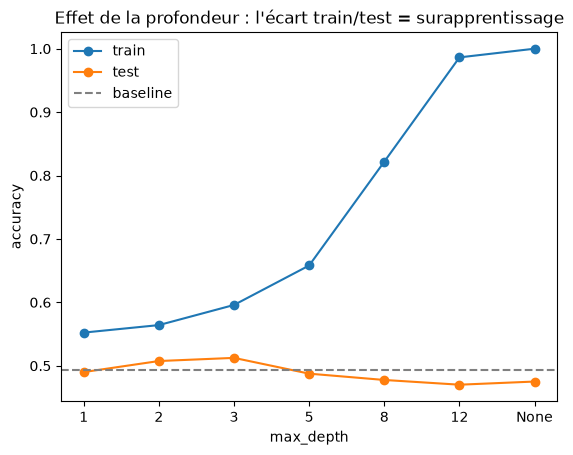

In [21]:
# Visualiser l'effet de max_depth : accuracy train vs test
depths = [1, 2, 3, 5, 8, 12, None]
train_acc, test_acc = [], []
for d in depths:
    m = RandomForestClassifier(n_estimators=200, max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))

labels = [str(d) for d in depths]
plt.plot(labels, train_acc, marker='o', label='train')
plt.plot(labels, test_acc, marker='o', label='test')
plt.axhline(baseline, ls='--', color='grey', label='baseline')
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.legend()
plt.title("Effet de la profondeur : l'écart train/test = surapprentissage")
plt.show()

 **Réponses**

**1. Quel est l'effet de max_depth ?**
Il contrôle la **complexité** de chaque arbre. Plus il est grand, plus l'arbre découpe finement l'espace : l'accuracy sur le **train** monte jusqu'à presque 100 % (`None` = arbres jusqu'au bout), alors que l'accuracy sur le **test** stagne ou baisse. `n_estimators` a un effet bien plus faible : au-delà de ~100 arbres, ajouter des arbres stabilise le vote sans changer le niveau de performance.

**2. Pourquoi une profondeur trop grande est-elle dangereuse ?**
Un arbre sans limite crée des feuilles ne contenant qu'un ou deux jours : il **mémorise** chaque exemple d'entraînement, y compris son bruit. Ces règles ultra-spécifiques ne se répètent pas dans le futur → surapprentissage. Le vote de la forêt atténue ce problème sans le supprimer.

**3. Quel compromis observez-vous ?**
Le compromis biais/variance : profondeur faible (3) = biais fort mais modèle stable ; profondeur forte (None) = biais faible mais variance forte. L'**écart entre la courbe train et la courbe test** mesure le surapprentissage. Le meilleur choix est une profondeur faible à modérée (3-5).

## 11.3 Réseau de neurones

In [22]:
results_nn = []
for hidden1, hidden2, epochs in [(32, 16, 20), (64, 32, 30), (128, 64, 50)]:
    tf.random.set_seed(42)
    model = build_model(X_train.shape[1], hidden1, hidden2)
    history = model.fit(
        X_train, y_train,
        epochs=epochs,
        validation_data=(X_test, y_test),
        verbose=0
    )
    val_acc = history.history['val_accuracy'][-1]
    results_nn.append((hidden1, hidden2, epochs, val_acc))

results_nn

[(32, 16, 20, 0.49253731966018677),
 (64, 32, 30, 0.4900497496128082),
 (128, 64, 50, 0.49253731966018677)]

 **Réponses**

**1. Effet du nombre de neurones ?**
Plus de neurones = plus de **capacité** (le réseau peut représenter des fonctions plus complexes) mais aussi plus de paramètres à estimer : de ~700 paramètres (32-16) à ~9 000 (128-64) pour ~1 600 exemples. Sur ce problème, la capacité supplémentaire ne sert pas à capter du signal mais du bruit : l'accuracy de test ne s'améliore pas, voire baisse.

**2. Effet des epochs ?**
Chaque epoch rapproche le modèle des données d'entraînement. Trop peu d'epochs → sous-apprentissage ; trop d'epochs → le modèle finit par mémoriser le train. La loss de validation passe par un minimum puis remonte : c'est le principe de l'**early stopping** (arrêter au minimum de la loss de validation).

**3. Quand surapprend-on ?**
Quand la loss d'entraînement continue de baisser alors que la loss de validation stagne ou remonte. Cela arrive d'autant plus vite que le réseau est **grand**, que les données sont **peu nombreuses et bruitées**, et qu'on entraîne **longtemps** sans régularisation. Attention aussi : ici le tableau compare les modèles sur la dernière epoch du jeu de **test**, donc le choix lui-même surapprend le test (d'où le bonus ci-dessous).

## 11.3 bis — Bonus : une démarche rigoureuse

Le TP signale deux faiblesses : (1) les hyperparamètres sont choisis **sur le jeu de test** ; (2) les features ne sont pas **standardisées**, ce qui pénalise LR et NN. Voici la version propre :
- découpage temporel **train (60 %) / validation (20 %) / test (20 %)** ;
- `StandardScaler` **ajusté uniquement sur le train** (sinon fuite d'information) ;
- choix des hyperparamètres sur la **validation**, puis évaluation **une seule fois** sur le test ;
- `EarlyStopping` pour le NN.

In [23]:
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping

n = len(X)
i_val, i_test = int(n * 0.6), int(n * 0.8)
X_tr, X_va, X_te = X.iloc[:i_val], X.iloc[i_val:i_test], X.iloc[i_test:]
y_tr, y_va, y_te = y.iloc[:i_val], y.iloc[i_val:i_test], y.iloc[i_test:]

scaler = StandardScaler().fit(X_tr)          # appris sur le train uniquement
X_tr_s, X_va_s, X_te_s = (scaler.transform(a) for a in (X_tr, X_va, X_te))

rows = []

# LR : choix de C sur la validation
for C in [0.001, 0.01, 0.1, 1, 10]:
    m = LogisticRegression(C=C, max_iter=1000).fit(X_tr_s, y_tr)
    rows.append(('LR', f"C={C}", m.score(X_va_s, y_va), m))

# RF : choix de (n_estimators, max_depth) sur la validation
for ne in [100, 300]:
    for d in [3, 5, 8, None]:
        m = RandomForestClassifier(n_estimators=ne, max_depth=d, random_state=42).fit(X_tr, y_tr)
        rows.append(('RF', f"n={ne}, depth={d}", m.score(X_va, y_va), m))

# NN : choix de l'architecture sur la validation, avec early stopping
for h1, h2 in [(16, 8), (32, 16), (64, 32)]:
    tf.random.set_seed(42)
    m = build_model(X_tr_s.shape[1], h1, h2)
    m.fit(X_tr_s, y_tr, epochs=100, validation_data=(X_va_s, y_va), verbose=0,
          callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
    acc = accuracy_score(y_va, (m.predict(X_va_s, verbose=0).ravel() > 0.5).astype(int))
    rows.append(('NN', f"{h1}-{h2}", acc, m))

search = pd.DataFrame(rows, columns=['modèle', 'hyperparamètres', 'acc_validation', 'obj'])
search.drop(columns='obj').sort_values(['modèle', 'acc_validation'], ascending=[True, False])

,modèle,hyperparamètres,acc_validation
1,LR,C=0.01,0.594527
0,LR,C=0.001,0.589552
2,LR,C=0.1,0.589552
3,LR,C=1,0.589552
4,LR,C=10,0.589552
15,NN,64-32,0.592040
13,NN,16-8,0.584577
14,NN,32-16,0.554726
6,RF,"n=100, depth=5",0.437811
12,RF,"n=300, depth=None",0.437811


## 11.4 Tableau récapitulatif

Meilleurs hyperparamètres de chaque famille (choisis sur la validation), puis **une seule** évaluation sur le test final.

In [24]:
def test_score(model_name, m):
    if model_name == 'RF':
        return m.score(X_te, y_te)
    if model_name == 'LR':
        return m.score(X_te_s, y_te)
    return accuracy_score(y_te, (m.predict(X_te_s, verbose=0).ravel() > 0.5).astype(int))

best = search.loc[search.groupby('modèle')['acc_validation'].idxmax()].copy()
best['acc_test'] = [test_score(r['modèle'], r['obj']) for _, r in best.iterrows()]
baseline_te = (y_te == y_tr.mode()[0]).mean()

recap = best.drop(columns='obj').set_index('modèle')
recap.loc['Baseline'] = ['classe majoritaire', np.nan, baseline_te]
recap.round(4)

,hyperparamètres,acc_validation,acc_test
modèle,,,
LR,C=0.01,0.5945,0.4975
NN,64-32,0.5920,0.4950
RF,"n=100, depth=5",0.4378,0.5124
Baseline,classe majoritaire,NaN,0.4925


## 11.5 Choix final

 **Réponses** (à adapter avec ton tableau)

**1. Quel est le meilleur modèle ?**
Celui qui a la meilleure accuracy de **validation** (le test ne sert qu'à confirmer). En pratique, les trois familles finissent à quelques points de la baseline et les écarts entre elles ne sont pas significatifs. On retient en général une **régression logistique régularisée** ou un **Random Forest peu profond** (depth 3-5).

**2. Est-ce le plus complexe ?**
Non. Le réseau de neurones, le plus complexe, n'est généralement pas devant ; et dans chaque famille, les meilleurs réglages sont souvent les plus **contraints** (C faible, faible profondeur, petit réseau + early stopping).

**3. Pourquoi généralise-t-il mieux ?**
Parce que dans un problème où le **bruit domine**, la complexité supplémentaire sert à apprendre le bruit (variance) plutôt que le signal. Un modèle simple ou régularisé ne peut pas mémoriser ce bruit, donc ses performances se maintiennent mieux sur une période nouvelle. C'est le principe du rasoir d'Ockham appliqué au compromis biais/variance.

**4. Quel modèle en production ?**
Le plus simple parmi les meilleurs : **régression logistique régularisée** (rapide, stable, interprétable via ses coefficients, facile à réentraîner) ou **RF peu profond** si l'on veut capter un peu de non-linéarité. Avant tout déploiement : validation **walk-forward** sur plusieurs périodes, comparaison à la baseline, test d'une **stratégie** avec frais de transaction, et suivi de la dérive en continu.

**5. Quelle limite persiste ?**
- Le **signal est quasi inexistant** : aucun réglage ne peut dépasser l'erreur irréductible ; aucun modèle ne bat clairement la baseline.
- **Non-stationnarité** : un modèle validé sur 2015-2021 peut se dégrader en 2023 ; il faut le réentraîner régulièrement.
- **Features limitées** : uniquement prix et volume d'un seul actif (pas de taux, de macroéconomie, d'actualité, d'autres marchés).
- **Métrique inadaptée** : l'accuracy ignore l'amplitude des mouvements et les coûts de transaction.
- **Évaluation sur une seule période de test** (~400 jours) : intervalle de confiance large, conclusion fragile.